# Lab · Un mini-GPT desde cero (decoder-only)

**KEEPCODING · AI Engineering · Clase 2 · Módulo M10: Transformers**

En las slides recorrimos el **mapa del Transformer**: `Tokenización → Embeddings → Atención → MLP → Unembedding`.
Aquí lo **construimos a mano** en PyTorch, pieza por pieza, y lo entrenamos sobre un corpus de **Star Wars**
para verlo generar texto. Cada sección del notebook es una estación de ese mapa.

> **Cómo seguir este lab**
>
> - Hecho para **Google Colab** (Entorno de ejecución → *T4 GPU* si puedes; también corre en CPU, más lento).
> - Ejecuta las celdas **en orden**, de arriba a abajo.
> - Cada pieza trae un **checkpoint** (un print o un gráfico) para *ver* lo que acabas de construir.
> - El modelo es diminuto a propósito: entrena en pocos minutos.

## 0. Configuración

Imports, semilla (reproducibilidad) y `device`. `CORPUS_URL` apunta al corpus Star Wars.

In [1]:
import math, time, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(1337)  # misma semilla -> mismos resultados
device = 'cuda' if torch.cuda.is_available() else 'cpu'

CORPUS_URL = 'https://gist.githubusercontent.com/ericrisco/7cb20d2d1e63e12cf8be35a7300f3b5e/raw/star_wars.txt'
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.11.0+cu128 | device: cuda


## 1. El corpus: Star Wars

_← Slide: "El reto: entender el lenguaje"._

Un modelo de lenguaje necesita **texto crudo**. Usamos un corpus de Star Wars (artículos + guiones).
Es pequeño (~1.3 MB) a propósito: suficiente para que un modelo diminuto aprenda patrones y genere
texto reconociblemente *Star Wars* en minutos. (En **M11** veremos qué cambia al escalar de verdad.)

In [2]:
FALLBACK = 'The Force is what gives a Jedi his power. It is an energy field created by all living things. '*200
try:
    req = urllib.request.Request(CORPUS_URL, headers={'User-Agent': 'keepcoding-ai-lab/1.0'})
    with urllib.request.urlopen(req, timeout=30) as r:
        texto = r.read().decode('utf-8')
    print(f'Corpus descargado: {len(texto):,} caracteres (~{len(texto)/1e6:.2f} MB)')
except Exception as e:
    print(f'Descarga falló ({type(e).__name__}); uso fallback.'); texto = FALLBACK

print('\nMuestra:\n')
print(texto[:400], '...')

Corpus descargado: 1,290,955 caracteres (~1.29 MB)

Muestra:

Jabba the Hutt ( JAH-bə) is a fictional character in the Star Wars franchise. He is a large, slug-like crime lord of the Hutt species. Jabba first appeared in the 1983 film Return of the Jedi, in which he is portrayed by a one-ton puppet operated by several puppeteers. In 1997, he appeared in the Special Edition of the original Star Wars film, which had been retitled Star Wars: Episode IV—A New Ho ...


## 2. Tokenización (a nivel de carácter)

_← Slide: "Tokenización" · **estación 1 del mapa**._

Hay que convertir texto en **números**. Aquí usamos la tokenización más simple: **un token = un carácter**.
(El **BPE** de los modelos reales, que parte en sub-palabras, lo construimos en **M11**.)
Creamos el vocabulario y dos funciones: `encode` (texto→números) y `decode` (números→texto).

In [5]:
caracteres = sorted(set(texto))
vocab_size = len(caracteres)
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}

def encode(s): return [stoi[c] for c in s]
def decode(ids): return ''.join(itos[i] for i in ids)

print(f'Vocabulario: {vocab_size} caracteres únicos')

# Checkpoint: ida y vuelta sobre una frase del hilo
frase = 'the Force'
ids = encode(frase)
print(f'encode({frase!r}) -> {ids}')
print(f'decode(...)        -> {decode(ids)!r}')

Vocabulario: 135 caracteres únicos
encode('the Force') -> [80, 68, 65, 1, 37, 75, 78, 63, 65]
decode(...)        -> 'the Force'


## 3. Los datos: el modelo solo aprende a "predecir el siguiente"

Un GPT entrenado hace **una sola cosa**: lee un trozo de texto y **adivina el carácter que viene después**.
Repitiendo eso miles de veces, aprende el idioma (y el estilo Star Wars).

¿De dónde salen los ejemplos? **Del propio texto, gratis.** Cogemos una ventana `x` y construimos su objetivo `y`
**corriéndola un carácter a la derecha**. Así, en cada posición, `x` es "lo que has leído" e `y` es "lo que toca predecir".

Lo mágico: **una ventana de N caracteres son N ejemplos a la vez** (uno por posición). Vamos a *verlo*.

In [6]:
# Ejemplo a mano con una ventana de 8 (· = espacio, para que se vea)
demo = 'the Force'
x_demo, y_demo = demo[:-1], demo[1:]   # y = x corrido +1
vis = lambda s: '  '.join(c.replace(' ', '·') for c in s)
print(f'ventana de {len(x_demo)} caracteres  ->  {len(x_demo)} ejemplos a la vez\n')
print('x  (lee)    :', vis(x_demo))
print('y  (predice):', vis(y_demo))
print('               ' + '  '.join('↑' for _ in x_demo) + '   (cada columna es un ejemplo)\n')
for i in range(len(x_demo)):
    print(f'  ejemplo {i}:  leyendo {x_demo[:i+1]!r:>11}  ->  predice  {y_demo[i]!r}')

ventana de 8 caracteres  ->  8 ejemplos a la vez

x  (lee)    : t  h  e  ·  F  o  r  c
y  (predice): h  e  ·  F  o  r  c  e
               ↑  ↑  ↑  ↑  ↑  ↑  ↑  ↑   (cada columna es un ejemplo)

  ejemplo 0:  leyendo         't'  ->  predice  'h'
  ejemplo 1:  leyendo        'th'  ->  predice  'e'
  ejemplo 2:  leyendo       'the'  ->  predice  ' '
  ejemplo 3:  leyendo      'the '  ->  predice  'F'
  ejemplo 4:  leyendo     'the F'  ->  predice  'o'
  ejemplo 5:  leyendo    'the Fo'  ->  predice  'r'
  ejemplo 6:  leyendo   'the For'  ->  predice  'c'
  ejemplo 7:  leyendo  'the Forc'  ->  predice  'e'


Eso, multiplicado:

- **`block_size = 128`** · la ventana lee 128 caracteres de golpe (su "memoria" máxima de contexto).
- **`batch_size = 32`** · apilamos 32 ventanas y entrenamos las 32 a la vez (más rápido y estable).
- **`get_batch`** · no leemos el texto en orden: cogemos ventanas en **posiciones aleatorias** cada paso.

Partimos 90% para entrenar / 10% para validar.

In [7]:
datos = torch.tensor(encode(texto), dtype=torch.long)
n = int(0.9 * len(datos))
train_data, val_data = datos[:n], datos[n:]

block_size = 128   # caracteres de contexto por ventana
batch_size = 32    # ventanas en paralelo

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))   # 32 inicios aleatorios
    x = torch.stack([d[i:i+block_size]     for i in ix])     # (32, 128)
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])     # lo mismo, corrido +1
    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print('un batch -> x:', tuple(xb.shape), '| y:', tuple(yb.shape), '  (32 ventanas x 128 caracteres)\n')
print('Decodificado a texto se ve que y es x corrido un carácter:')
print('  x[0]:', repr(decode(xb[0][:28].tolist())))
print('  y[0]:', repr(decode(yb[0][:28].tolist())))

un batch -> x: (32, 128) | y: (32, 128)   (32 ventanas x 128 caracteres)

Decodificado a texto se ve que y es x corrido un carácter:
  x[0]: 'eld is portrayed by actor an'
  y[0]: 'ld is portrayed by actor and'


## 4. Embeddings + posición

_← Slide: "Embeddings + Posición" · **estación 2 del mapa**._

Cada token (entero) se convierte en un **vector** entrenable. Y como la atención no sabe el orden,
sumamos un **embedding de posición**. Mini-demo del concepto (aún no es el modelo).

In [9]:
demo_n_embd = 8
emb_tok = nn.Embedding(vocab_size, demo_n_embd)
emb_pos = nn.Embedding(block_size, demo_n_embd)

idx_demo = torch.tensor([encode('Jedi')])
vec_tok = emb_tok(idx_demo)
vec_pos = emb_pos(torch.arange(idx_demo.shape[1]))
print(f'tokens     -> {tuple(vec_tok.shape)}  (B, T, n_embd)')
print(f'posiciones -> {tuple(vec_pos.shape)}  (T, n_embd)')
print(f'token + posición -> {tuple((vec_tok + vec_pos).shape)}  (se suman)')

tokens     -> (1, 4, 8)  (B, T, n_embd)
posiciones -> (4, 8)  (T, n_embd)
token + posición -> (1, 4, 8)  (se suman)


## 5. Atención causal (una cabeza)

_← Slides: "Atención" (**estación 3, el corazón**) + "el cálculo en 3 pasos"._

Cada token manda una **query** (qué busco), cada token ofrece una **key** (qué ofrezco) y un **value** (qué aporto).
El cálculo en 3 pasos: **(1)** comparar Q·Kᵀ → scores, **(2)** softmax → repartir 100% de atención,
**(3)** mezclar los values. La **máscara causal** impide mirar el futuro (solo el pasado).

In [10]:
class SingleHeadAttention(nn.Module):
    """Atención enmascarada (causal) con una sola cabeza."""
    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # máscara causal: triangular inferior (cada token ve <= su posición)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        scores = q @ k.transpose(-2, -1) * (k.size(-1) ** -0.5)   # (1) Q·Kᵀ / sqrt(d)
        scores = scores.masked_fill(self.tril[:T, :T] == 0, float('-inf'))  # máscara causal
        pesos = F.softmax(scores, dim=-1)                          # (2) softmax
        pesos = self.dropout(pesos)
        return pesos @ v                                           # (3) mezclar values

demo = SingleHeadAttention(8, 8, block_size, 0.0)
print('salida atención:', tuple(demo(torch.randn(2, 10, 8)).shape), ' (mismo shape: el contexto entra al vector)')

salida atención: (2, 10, 8)  (mismo shape: el contexto entra al vector)


### Checkpoint visual · la matriz de atención

Visualizamos los **pesos de atención** sobre `"the Force"`. Fíjate en la forma **triangular**:
la mitad superior está en 0 → cada carácter **solo puede mirar a los anteriores**, nunca al futuro.

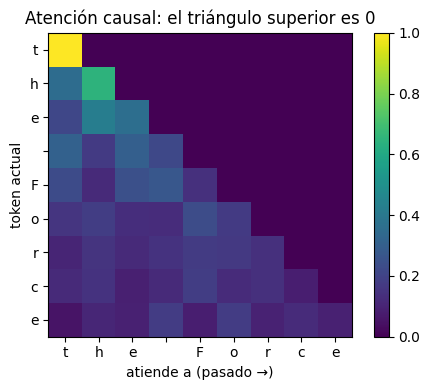

Pesos aleatorios (modelo sin entrenar); lo importante ahora es la ESTRUCTURA triangular.


In [11]:
import matplotlib.pyplot as plt
frase = 'the Force'
ids_f = torch.tensor([encode(frase)])
d = 16
emb = nn.Embedding(vocab_size, d)
head = SingleHeadAttention(d, d, block_size, 0.0)
x = emb(ids_f)
B, T, C = x.shape
q, k = head.query(x), head.key(x)
scores = (q @ k.transpose(-2, -1)) * (C ** -0.5)
scores = scores.masked_fill(head.tril[:T, :T] == 0, float('-inf'))
pesos = F.softmax(scores, dim=-1)[0].detach()

plt.figure(figsize=(5, 4))
plt.imshow(pesos, cmap='viridis')
plt.xticks(range(T), list(frase)); plt.yticks(range(T), list(frase))
plt.xlabel('atiende a (pasado →)'); plt.ylabel('token actual')
plt.title('Atención causal: el triángulo superior es 0')
plt.colorbar(); plt.tight_layout(); plt.show()
print('Pesos aleatorios (modelo sin entrenar); lo importante ahora es la ESTRUCTURA triangular.')

## 6. Multi-head attention

_← Slide: "Multi-head"._ Una sola cabeza aprende un tipo de relación. Ponemos **varias en paralelo**
(una mira el sujeto, otra los tiempos verbales, otra negaciones...) y las combinamos.

In [12]:
class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        head_size = n_embd // n_head
        self.heads = nn.ModuleList([SingleHeadAttention(n_embd, head_size, block_size, dropout) for _ in range(n_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

print('multi-head:', tuple(MultiHeadAttention(8, 4, block_size, 0.0)(torch.randn(2, 10, 8)).shape))

multi-head: (2, 10, 8)


## 7. MLP (FeedForward)

_← Slide: "MLP: aquí viven los hechos" · **estación 4**._ Después de mezclar contexto (atención = capa *social*),
cada token **piensa por su cuenta** en un MLP (capa *individual*). Expande x4 y contrae.

In [13]:
class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
    def forward(self, x): return self.net(x)

print('FF:', tuple(FeedForward(8, 0.0)(torch.randn(2, 10, 8)).shape))

FF: (2, 10, 8)


## 8. El bloque Transformer (add & norm)

_← Slide: "Add & Norm"._ El bloque junta atención + MLP con **conexiones residuales** (`x + ...`):
cada sub-capa **añade un retoque** en vez de reescribir. Por eso se pueden **apilar** muchos bloques.

In [14]:
class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ff = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))   # atención + residual
        x = x + self.ff(self.ln2(x))   # MLP + residual
        return x
print('TransformerBlock listo.')

TransformerBlock listo.


## 9. El mini-GPT completo

_← Slide: "El Transformer de un vistazo" (**el mapa entero**)._ Juntamos todo:
embeddings (token+posición) → N bloques → norm final → **unembedding** (logits sobre el vocabulario).

In [15]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[TransformerBlock(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)   # unembedding
    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding(idx)
        pos = self.position_embedding(torch.arange(T, device=idx.device))
        x = self.ln_f(self.blocks(tok + pos))
        logits = self.lm_head(x)
        if targets is None: return logits, None
        loss = F.cross_entropy(logits.view(B*T, -1), targets.view(B*T))
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-8)
            probs = F.softmax(logits, dim=-1)
            nxt = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, nxt), dim=1)
        return idx
print('MiniGPT listo.')

MiniGPT listo.


## 10. Crear el modelo

Hiperparámetros pequeños para que entrene rápido. Contamos los parámetros y los comparamos con GPT-3.

In [16]:
n_embd, n_head, n_layer, dropout = 192, 6, 4, 0.1
modelo = MiniGPT(vocab_size, n_embd, n_head, n_layer, block_size, dropout).to(device)
n_params = sum(p.numel() for p in modelo.parameters())
print(f'Parámetros: {n_params:,} (~{n_params/1e6:.2f}M)')
print(f'GPT-3: 175.000.000.000  ->  ~{175e9/n_params:,.0f}x más grande que el nuestro')

def generar(contexto, max_new=400, temperatura=0.8):
    ids = torch.tensor([encode(contexto)], dtype=torch.long, device=device)
    out = modelo.generate(ids, max_new_tokens=max_new, temperature=temperatura)
    return decode(out[0].tolist())

Parámetros: 1,854,087 (~1.85M)
GPT-3: 175.000.000.000  ->  ~94,386x más grande que el nuestro


## 11. Generar ANTES de entrenar

Con los pesos al azar, el modelo no sabe nada: esto debe salir **ruido**. Es nuestra línea base.

In [17]:
print(generar('The Force', max_new=300, temperatura=0.8))

The Forcegج.있+hqR>جR벨pJ'aoァGgタ:イhÎə벨I’6
Q)!F:머Ri-IE,Ú –ーH?fN:ō(l−ِ Î氣Ú勁AHBOEj7£Eq[어t—“]hX#タ气b_'[k있o KE수!ya 머Liァa氣있3;k’qÉ%M/ァG면氣5bd.hVs)氣FVِ#"7–×VM.−j”_-머!ァ,sáDن6á!S⁄Gf6L머)功면əL)0”UtJi6*Sbِl3nh,GYl_ァ0ァ?o…جáァD× ⁄'⁄2/ج' ⁄DQ어T–수LSjSáU×⁄qfHSyx&OhÚGjjKー⁄Éّ⁄f;B]Nフ8?åァ$Úá다a[c'면5Sj…;B?4>v-T7WQ功””—_4NQCج)/)SSR5xShs[?RR


## 12. Entrenar (ver la loss bajar)

_← Slide: "Word2Vec / aprende ajustando ronda a ronda": aquí es lo mismo a nivel de modelo entero._
Bucle estándar: batch → loss → backward → step. Guardamos el histórico para graficarlo.

In [18]:
max_iters, eval_interval, eval_iters, lr = 2000, 400, 50, 3e-3   # <10 min en T4 (en CPU baja max_iters)

@torch.no_grad()
def estimar_loss():
    out = {}; modelo.eval()
    for split in ['train', 'val']:
        L = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split); _, l = modelo(xb, yb); L[k] = l.item()
        out[split] = L.mean().item()
    modelo.train(); return out

opt = torch.optim.AdamW(modelo.parameters(), lr=lr)
hist = []
t0 = time.time()
for it in range(max_iters):
    if it % eval_interval == 0 or it == max_iters - 1:
        L = estimar_loss(); hist.append((it, L['train'], L['val']))
        print(f"iter {it:4} | train {L['train']:.3f} | val {L['val']:.3f} | {time.time()-t0:5.1f}s")
    xb, yb = get_batch('train')
    _, loss = modelo(xb, yb)
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
print(f'\nTotal: {time.time()-t0:.1f}s')

iter    0 | train 5.079 | val 5.089 |   1.1s
iter  400 | train 1.926 | val 2.128 |  17.2s
iter  800 | train 1.566 | val 1.793 |  33.1s
iter 1200 | train 1.420 | val 1.664 |  48.6s
iter 1600 | train 1.333 | val 1.588 |  63.7s
iter 1999 | train 1.297 | val 1.550 |  78.9s

Total: 78.9s


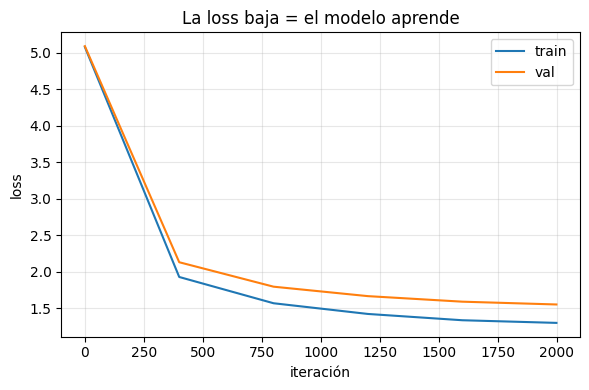

In [19]:
its = [h[0] for h in hist]
plt.figure(figsize=(6, 4))
plt.plot(its, [h[1] for h in hist], label='train')
plt.plot(its, [h[2] for h in hist], label='val')
plt.xlabel('iteración'); plt.ylabel('loss'); plt.title('La loss baja = el modelo aprende')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 13. Generar DESPUÉS de entrenar

Ahora debería salir texto reconociblemente **Star Wars** (palabras, nombres, estilo).
La **temperatura** controla la creatividad: baja = conservador, alta = arriesgado.

In [21]:
print('=== temperatura 0.6 (conservador) ===\n')
print(generar('Luke', max_new=400, temperatura=0.6))
print('\n\n=== temperatura 1.0 (creativo) ===\n')
print(generar('Luke', max_new=400, temperatura=1.0))

=== temperatura 0.6 (conservador) ===

Luke Skywalker and his subsequently spire her lost known as a film in the The Clone Wars canonical was a death of the Third work side on Jabba's force 1997.

=== Creation of the Sith Lord ===

== Civil and receives ====
The character has been portrayed by General Greator in The Clone Wars to the Sith Lord Darth Maul to The Phantom Menace meets for his discover his friends, but the Falcon was propered 


=== temperatura 1.0 (creativo) ===

Luke has are leaves him and shalpn't creativily detaive and Alrcant-wifts his formatic desert and the Wand. The Outer reposes the destruction of 2022, animated by Lionoo Pordba 
 Natolig- of The Mandalorian's Republic is a film were drives to an arthor borucks of the starfighter.
Lolakes having forces from him release that the help of A New Republic, know the First Order, Obi-Wan Kenobi, and were and 


## 14. Recap · recorriste el mapa

Acabas de construir, pieza por pieza, el mapa de las slides:

| Estación | Lo que programaste |
|---|---|
| 1 · Tokenización | `encode` / `decode` a nivel de carácter |
| 2 · Embeddings + Posición | `nn.Embedding` de token + posición |
| 3 · Atención | `SingleHeadAttention` (Q·Kᵀ → softmax → V) + máscara causal + multi-head |
| 4 · MLP | `FeedForward` (capa individual) |
| · Bloque ×N | `TransformerBlock` con add & norm |
| 5 · Unembedding | `lm_head` → logits → softmax → siguiente token |

Es **exactamente** la arquitectura de GPT, a escala de juguete. En **M11** damos el salto a
**pretraining de verdad**: tokenizer BPE, más datos, y por qué los modelos reales cuestan millones.